<a href="https://colab.research.google.com/github/antonioboboc/covd19-ct-scan-segmentation/blob/main/notebooks/02_preprocesare_date.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

url_partitii = (
    "https://raw.githubusercontent.com/antonioboboc/"
    "covd19-ct-scan-segmentation/main/splits/partitii_ct.csv"
)

tabel_partitii = pd.read_csv(url_partitii)

print(f"Perechi CT–mască: {len(tabel_partitii)}")
print(tabel_partitii["partitie"].value_counts().to_string())
display(tabel_partitii.head(3))

Perechi CT–mască: 2729
partitie
Antrenare    1837
Test          591
Validare      301


,imagine,masca,grup,partitie
0,frames/Jun_coronacases_case10_100.png,masks/Jun_coronacases_case10_100.png,Jun_coronacases_case10,Antrenare
1,frames/Jun_coronacases_case10_101.png,masks/Jun_coronacases_case10_101.png,Jun_coronacases_case10,Antrenare
2,frames/Jun_coronacases_case10_102.png,masks/Jun_coronacases_case10_102.png,Jun_coronacases_case10,Antrenare


In [2]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

folder_date = Path("/content/ct_lesiuni")
arhiva = Path("/content/ct_lesiuni.zip")
url_date = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "maedemaftouni/covid19-ct-scan-lesion-segmentation-dataset"
)

cai = pd.concat([tabel_partitii["imagine"], tabel_partitii["masca"]])
lipsa = [cale for cale in cai if not (folder_date / cale).is_file()]

if lipsa:
    if not arhiva.is_file():
        print("Descarc arhiva Kaggle...")
        temporar = arhiva.with_suffix(".part")
        urlretrieve(url_date, temporar)
        temporar.replace(arhiva)

    print("Extrag imaginile și măștile...")
    with ZipFile(arhiva) as zip_date:
        zip_date.extractall(folder_date)

lipsa = [cale for cale in cai if not (folder_date / cale).is_file()]
print(f"Fișiere disponibile: {len(cai) - len(lipsa)} din {len(cai)}")
print(f"Fișiere lipsă: {len(lipsa)}")

Descarc arhiva Kaggle...
Extrag imaginile și măștile...
Fișiere disponibile: 5458 din 5458
Fișiere lipsă: 0


Dimensiune originală: 512 × 512
Dimensiune după preprocesare: (256, 256)
Intervalul intensităților CT: 0.000–0.847
Valori în masca binară: [0 1]


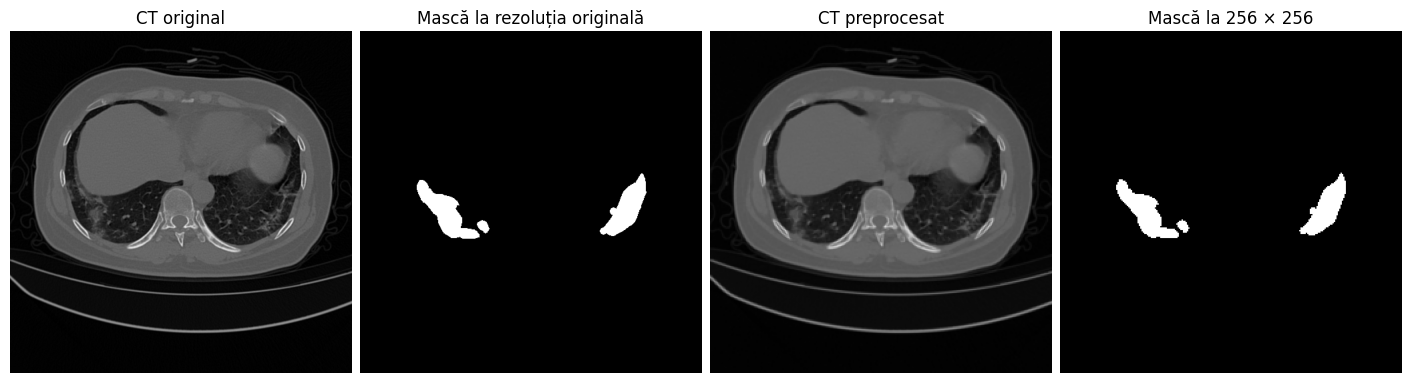

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

exemplu = tabel_partitii.loc[tabel_partitii["partitie"] == "Antrenare"].iloc[0]
dimensiune = (256, 256)

with Image.open(folder_date / exemplu["imagine"]) as fisier_ct:
    ct_original = fisier_ct.convert("L")

with Image.open(folder_date / exemplu["masca"]) as fisier_masca:
    masca_originala = fisier_masca.convert("L")

ct_preprocesat = np.asarray(
    ct_original.resize(dimensiune, Image.Resampling.BILINEAR),
    dtype=np.float32,
) / 255.0

masca_redimensionata = masca_originala.resize(dimensiune, Image.Resampling.NEAREST)
masca_binara = (np.asarray(masca_redimensionata) > 0).astype(np.uint8)

print(f"Dimensiune originală: {ct_original.width} × {ct_original.height}")
print(f"Dimensiune după preprocesare: {ct_preprocesat.shape}")
print(f"Intervalul intensităților CT: {ct_preprocesat.min():.3f}–{ct_preprocesat.max():.3f}")
print(f"Valori în masca binară: {np.unique(masca_binara)}")

fig, axe = plt.subplots(1, 4, figsize=(14, 4), layout="constrained")

axe[0].imshow(ct_original, cmap="gray", vmin=0, vmax=255)
axe[0].set_title("CT original")
axe[1].imshow(np.asarray(masca_originala) > 0, cmap="gray", vmin=0, vmax=1)
axe[1].set_title("Mască la rezoluția originală")
axe[2].imshow(ct_preprocesat, cmap="gray", vmin=0, vmax=1)
axe[2].set_title("CT preprocesat")
axe[3].imshow(masca_binara, cmap="gray", vmin=0, vmax=1)
axe[3].set_title("Mască la 256 × 256")

for axa in axe:
    axa.axis("off")

plt.show()


In [4]:
randuri_antrenare = tabel_partitii[tabel_partitii["partitie"] == "Antrenare"]
masti_cu_leziune = 0
masti_devenite_goale = []

for cale_relativa in randuri_antrenare["masca"]:
    with Image.open(folder_date / cale_relativa) as fisier:
        original = fisier.convert("L")
        redimensionat = original.resize(dimensiune, Image.Resampling.NEAREST)

    if np.any(np.asarray(original) > 0):
        masti_cu_leziune += 1
        if not np.any(np.asarray(redimensionat) > 0):
            masti_devenite_goale.append(cale_relativa)

print(f"Măști verificate: {len(randuri_antrenare)}")
print(f"Măști cu leziune înainte de redimensionare: {masti_cu_leziune}")
print(f"Măști devenite complet goale la 256 × 256: {len(masti_devenite_goale)}")

if masti_devenite_goale:
    print("Exemple:", masti_devenite_goale[:5])

Măști verificate: 1837
Măști cu leziune înainte de redimensionare: 1836
Măști devenite complet goale la 256 × 256: 0


In [5]:
def incarca_pereche(cale_imagine, cale_masca):
    with Image.open(folder_date / cale_imagine) as fisier_ct:
        ct = fisier_ct.convert("L").resize(
            dimensiune, Image.Resampling.BILINEAR
        )
        imagine = np.asarray(ct, dtype=np.float32) / 255.0

    with Image.open(folder_date / cale_masca) as fisier_masca:
        masca = fisier_masca.convert("L").resize(
            dimensiune, Image.Resampling.NEAREST
        )
        etichete = (np.asarray(masca) > 0).astype(np.float32)

    return imagine[..., np.newaxis], etichete[..., np.newaxis]


imagine, masca = incarca_pereche(exemplu["imagine"], exemplu["masca"])

print(f"Imagine: {imagine.shape}, tip {imagine.dtype}")
print(f"Mască: {masca.shape}, tip {masca.dtype}")
print(f"Valori în mască: {np.unique(masca)}")


Imagine: (256, 256, 1), tip float32
Mască: (256, 256, 1), tip float32
Valori în mască: [0. 1.]


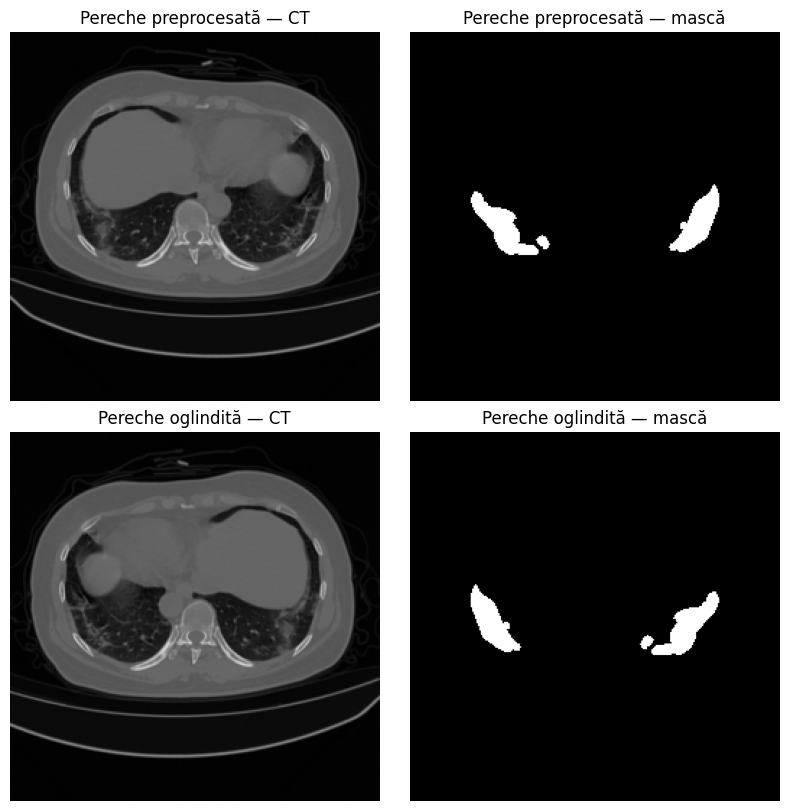

In [6]:
def oglindeste_orizontal(imagine, masca):
    imagine_oglindita = imagine[:, ::-1, :].copy()
    masca_oglindita = masca[:, ::-1, :].copy()
    return imagine_oglindita, masca_oglindita


imagine_oglindita, masca_oglindita = oglindeste_orizontal(imagine, masca)

fig, axe = plt.subplots(2, 2, figsize=(8, 8), layout="constrained")

for rand, (ct, etichete, titlu) in enumerate([
    (imagine, masca, "Pereche preprocesată"),
    (imagine_oglindita, masca_oglindita, "Pereche oglindită"),
]):
    axe[rand, 0].imshow(ct[..., 0], cmap="gray", vmin=0, vmax=1)
    axe[rand, 0].set_title(f"{titlu} — CT")
    axe[rand, 1].imshow(etichete[..., 0], cmap="gray", vmin=0, vmax=1)
    axe[rand, 1].set_title(f"{titlu} — mască")

    for axa in axe[rand]:
        axa.axis("off")

plt.show()

In [7]:
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

marime_lot = 8
forma_pereche = (256, 256, 1)


def incarca_pentru_tensorflow(cale_ct, cale_masca):
    # TensorFlow transmite căile către funcția Python ca text codificat.
    def citeste(ct, masca):
        return incarca_pereche(ct.decode("utf-8"), masca.decode("utf-8"))

    ct, masca = tf.numpy_function(
        citeste, [cale_ct, cale_masca], [tf.float32, tf.float32]
    )
    ct.set_shape(forma_pereche)
    masca.set_shape(forma_pereche)
    return ct, masca


def augmentare_aleatorie(ct, masca):
    # Punem imaginea și masca în două canale ale aceluiași tensor,
    # ca decizia de oglindire să fie aceeași pentru ambele.
    pereche = tf.concat([ct, masca], axis=-1)
    pereche = tf.image.random_flip_left_right(pereche)
    return pereche[..., :1], pereche[..., 1:]


def creeaza_set(nume_partitie):
    randuri = tabel_partitii[tabel_partitii["partitie"] == nume_partitie]
    set_date = tf.data.Dataset.from_tensor_slices(
        (randuri["imagine"].tolist(), randuri["masca"].tolist())
    )

    if nume_partitie == "Antrenare":
        set_date = set_date.shuffle(len(randuri), seed=42)

    set_date = set_date.map(incarca_pentru_tensorflow)

    if nume_partitie == "Antrenare":
        set_date = set_date.map(augmentare_aleatorie)

    return set_date.batch(marime_lot).prefetch(tf.data.AUTOTUNE)


set_antrenare = creeaza_set("Antrenare")
set_validare = creeaza_set("Validare")
set_test = creeaza_set("Test")

imagini_lot, masti_lot = next(iter(set_antrenare))
print("Lot de imagini:", imagini_lot.shape)
print("Lot de măști:", masti_lot.shape)


Lot de imagini: (8, 256, 256, 1)
Lot de măști: (8, 256, 256, 1)
